In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual style setup
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load the dataset (this has 500,000+ rows, so it will take ~15-20 seconds to load)
df = pd.read_excel('data/Online Retail.xlsx')

print(f"Total Transactions (Rows): {df.shape[0]:,}")
print(f"Total Columns: {df.shape[1]}")

# Show the first 5 receipts
df.head()

Total Transactions (Rows): 541,909
Total Columns: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
# Check data types and how many non-null values each column has
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [5]:
# Statistical summary for numerical columns (Quantity, UnitPrice)
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [6]:
# 1. Missing values count and percentage
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Percentage (%)': (df.isnull().sum() / len(df) * 100).round(2)
})
print("=== Missing Values ===")
print(missing[missing['Missing_Count'] > 0])

# 2. Check for duplicate rows
duplicates = df.duplicated().sum()
print(f"\nTotal Duplicate Rows: {duplicates:,} ({(duplicates / len(df) * 100):.2f}%)")

=== Missing Values ===
             Missing_Count  Percentage (%)
Description           1454            0.27
CustomerID          135080           24.93

Total Duplicate Rows: 5,268 (0.97%)


In [7]:
# Cancelled orders have InvoiceNo starting with 'C'
df['Is_Cancelled'] = df['InvoiceNo'].astype(str).str.startswith('C')

total_invoices = df['InvoiceNo'].nunique()
cancelled_invoices = df[df['Is_Cancelled']]['InvoiceNo'].nunique()
cancel_pct = (cancelled_invoices / total_invoices) * 100

print(f"Total Unique Invoices: {total_invoices:,}")
print(f"Cancelled Invoices: {cancelled_invoices:,}")
print(f"Cancellation Rate: {cancel_pct:.2f}%")

Total Unique Invoices: 25,900
Cancelled Invoices: 3,836
Cancellation Rate: 14.81%


In [8]:
# 1. Start by dropping duplicates
df_clean = df.drop_duplicates().copy()

# 2. Filter for valid sales (positive quantity, positive unit price, not cancelled)
df_clean = df_clean[
    (df_clean['Quantity'] > 0) & 
    (df_clean['UnitPrice'] > 0) & 
    (~df_clean['Is_Cancelled'])
].copy()

# 3. Clean up text columns
df_clean['Description'] = df_clean['Description'].str.strip()

# 4. Feature Engineering: Create TotalSales column
df_clean['TotalSales'] = df_clean['Quantity'] * df_clean['UnitPrice']

# 5. Time-based features
df_clean['Year'] = df_clean['InvoiceDate'].dt.year
df_clean['Month'] = df_clean['InvoiceDate'].dt.month
df_clean['YearMonth'] = df_clean['InvoiceDate'].dt.to_period('M')
df_clean['DayOfWeek'] = df_clean['InvoiceDate'].dt.day_name()
df_clean['Hour'] = df_clean['InvoiceDate'].dt.hour

print(f"Original Records: {len(df):,}")
print(f"Cleaned Valid Sales Records: {len(df_clean):,}")
print(f"Records Removed (cancellations/duplicates/adjustments): {len(df) - len(df_clean):,}")

# Peek at the new columns
df_clean[['InvoiceNo', 'Description', 'Quantity', 'UnitPrice', 'TotalSales', 'YearMonth', 'DayOfWeek', 'Hour']].head()

Original Records: 541,909
Cleaned Valid Sales Records: 524,878
Records Removed (cancellations/duplicates/adjustments): 17,031


,InvoiceNo,Description,Quantity,UnitPrice,TotalSales,YearMonth,DayOfWeek,Hour
0,536365,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30,2010-12,Wednesday,8
1,536365,WHITE METAL LANTERN,6,3.39,20.34,2010-12,Wednesday,8
2,536365,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00,2010-12,Wednesday,8
3,536365,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34,2010-12,Wednesday,8
4,536365,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34,2010-12,Wednesday,8


In [9]:
# 1. Question 5: Average Order Value (AOV)
order_totals = df_clean.groupby('InvoiceNo')['TotalSales'].sum()
aov = order_totals.mean()
median_order = order_totals.median()
print(f"=== Order Value Statistics ===")
print(f"Average Order Value (AOV): £{aov:,.2f}")
print(f"Median Order Value: £{median_order:,.2f}\n")

# 2. Questions 1 & 4: Top 10 Products by Revenue & Quantity
top_products_rev = df_clean.groupby('Description')['TotalSales'].sum().sort_values(ascending=False).head(10)
top_products_qty = df_clean.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(10)

print("=== Top 5 Products by Revenue ===")
for i, (prod, rev) in enumerate(top_products_rev.head(5).items(), 1):
    print(f"{i}. {prod}: £{rev:,.2f}")

print("\n=== Top 5 Products by Quantity Sold ===")
for i, (prod, qty) in enumerate(top_products_qty.head(5).items(), 1):
    print(f"{i}. {prod}: {qty:,} units")

# 3. Question 2: Top 5 Countries by Revenue
country_rev = df_clean.groupby('Country')['TotalSales'].sum().sort_values(ascending=False)
total_rev = df_clean['TotalSales'].sum()
print("\n=== Top 5 Countries by Revenue ===")
for i, (country, rev) in enumerate(country_rev.head(5).items(), 1):
    pct = (rev / total_rev) * 100
    print(f"{i}. {country}: £{rev:,.2f} ({pct:.1f}% of total)")

=== Order Value Statistics ===
Average Order Value (AOV): £533.17
Median Order Value: £303.30

=== Top 5 Products by Revenue ===
1. DOTCOM POSTAGE: £206,248.77
2. REGENCY CAKESTAND 3 TIER: £174,156.54
3. PAPER CRAFT , LITTLE BIRDIE: £168,469.60
4. WHITE HANGING HEART T-LIGHT HOLDER: £106,236.72
5. PARTY BUNTING: £99,445.23

=== Top 5 Products by Quantity Sold ===
1. PAPER CRAFT , LITTLE BIRDIE: 80,995 units
2. MEDIUM CERAMIC TOP STORAGE JAR: 78,033 units
3. WORLD WAR 2 GLIDERS ASSTD DESIGNS: 54,951 units
4. JUMBO BAG RED RETROSPOT: 48,371 units
5. WHITE HANGING HEART T-LIGHT HOLDER: 37,872 units

=== Top 5 Countries by Revenue ===
1. United Kingdom: £9,001,744.09 (84.6% of total)
2. Netherlands: £285,446.34 (2.7% of total)
3. EIRE: £283,140.52 (2.7% of total)
4. Germany: £228,678.40 (2.1% of total)
5. France: £209,625.37 (2.0% of total)


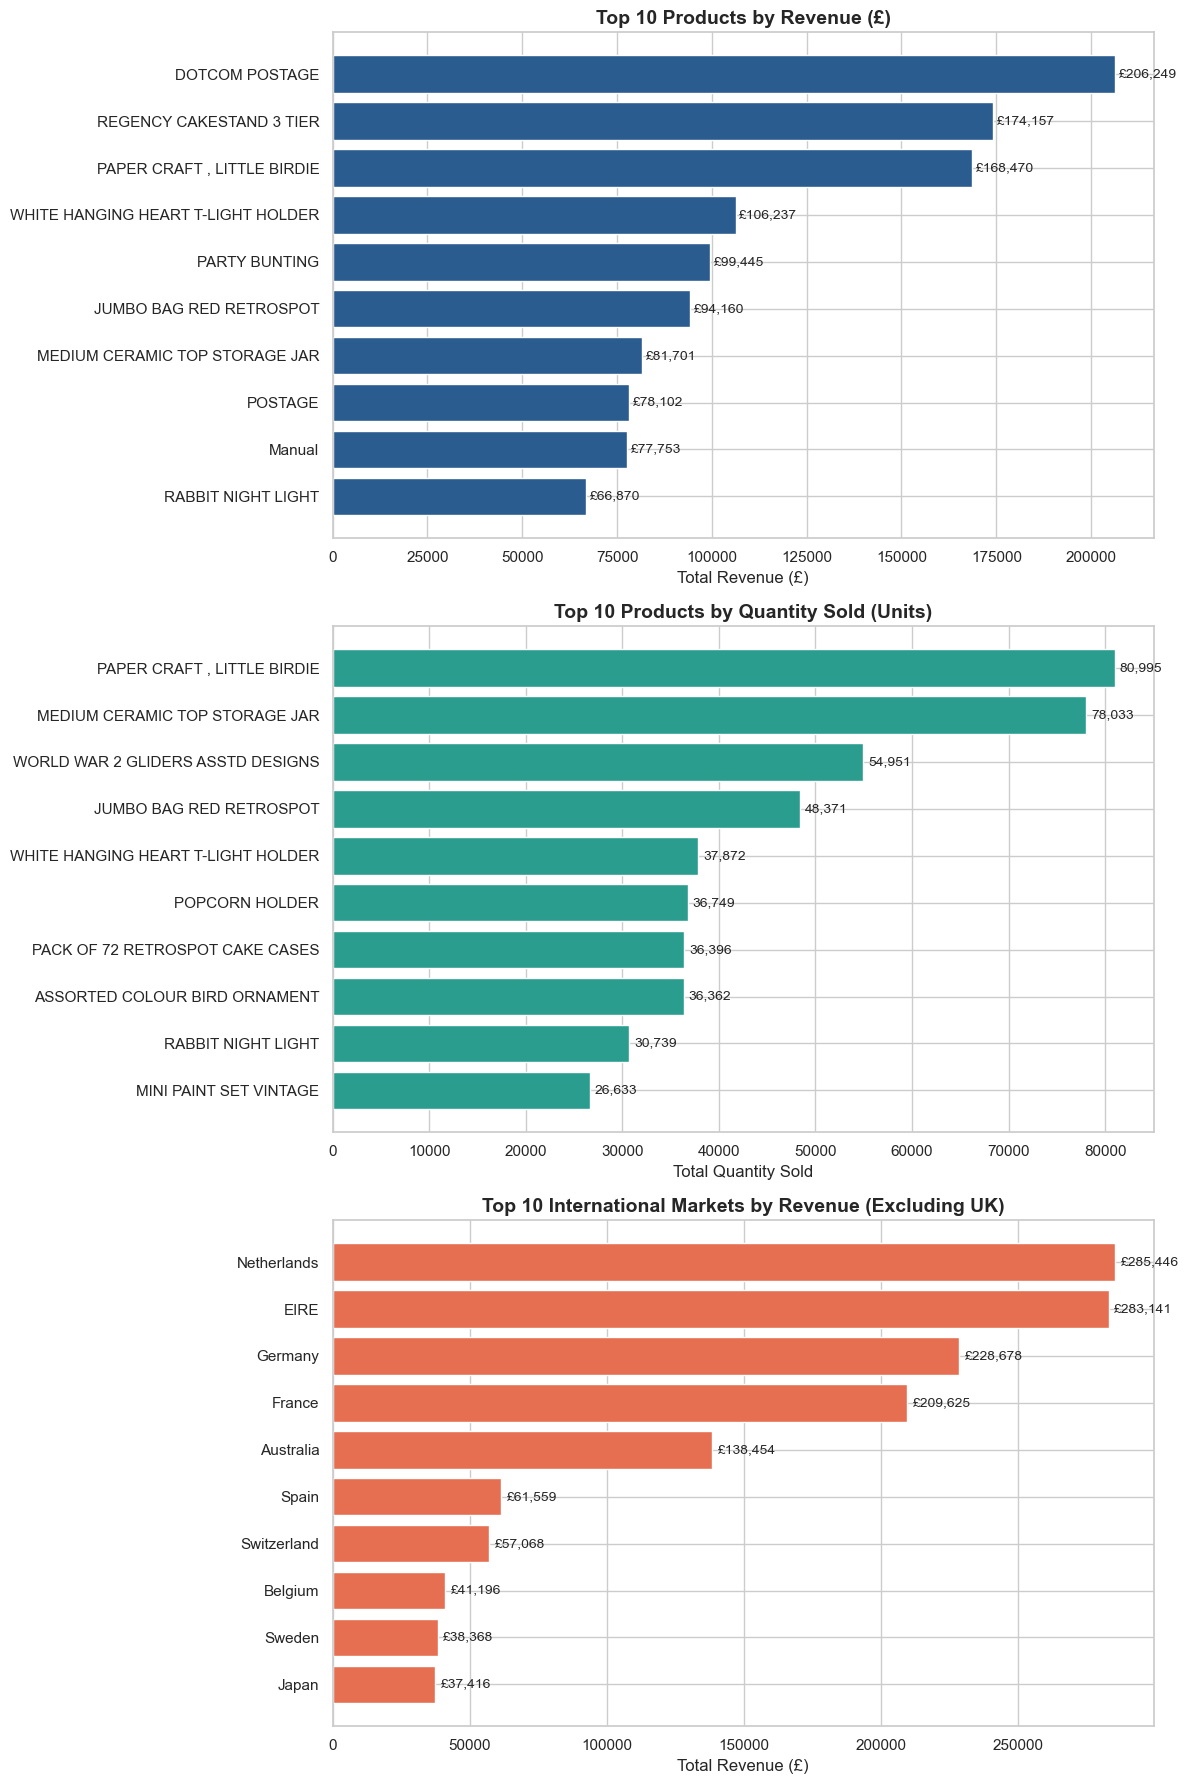

In [10]:
# Create a 3-panel figure for our 3 Bar Charts
fig, axes = plt.subplots(3, 1, figsize=(12, 18))
plt.subplots_adjust(hspace=0.4)

# 1. Bar Chart: Top 10 Products by Revenue
top_rev = df_clean.groupby('Description')['TotalSales'].sum().nlargest(10).sort_values()
axes[0].barh(top_rev.index, top_rev.values, color='#2b5c8f')
axes[0].set_title('Top 10 Products by Revenue (£)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Total Revenue (£)', fontsize=12)
for i, v in enumerate(top_rev.values):
    axes[0].text(v + 1000, i, f"£{v:,.0f}", va='center', fontsize=10)

# 2. Bar Chart: Top 10 Products by Quantity Sold
top_qty = df_clean.groupby('Description')['Quantity'].sum().nlargest(10).sort_values()
axes[1].barh(top_qty.index, top_qty.values, color='#2a9d8f')
axes[1].set_title('Top 10 Products by Quantity Sold (Units)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Total Quantity Sold', fontsize=12)
for i, v in enumerate(top_qty.values):
    axes[1].text(v + 500, i, f"{v:,}", va='center', fontsize=10)

# 3. Bar Chart: Top 10 International Markets by Revenue (Excl. UK)
intl_rev = df_clean[df_clean['Country'] != 'United Kingdom'].groupby('Country')['TotalSales'].sum().nlargest(10).sort_values()
axes[2].barh(intl_rev.index, intl_rev.values, color='#e76f51')
axes[2].set_title('Top 10 International Markets by Revenue (Excluding UK)', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Total Revenue (£)', fontsize=12)
for i, v in enumerate(intl_rev.values):
    axes[2].text(v + 2000, i, f"£{v:,.0f}", va='center', fontsize=10)

plt.tight_layout()
plt.show()

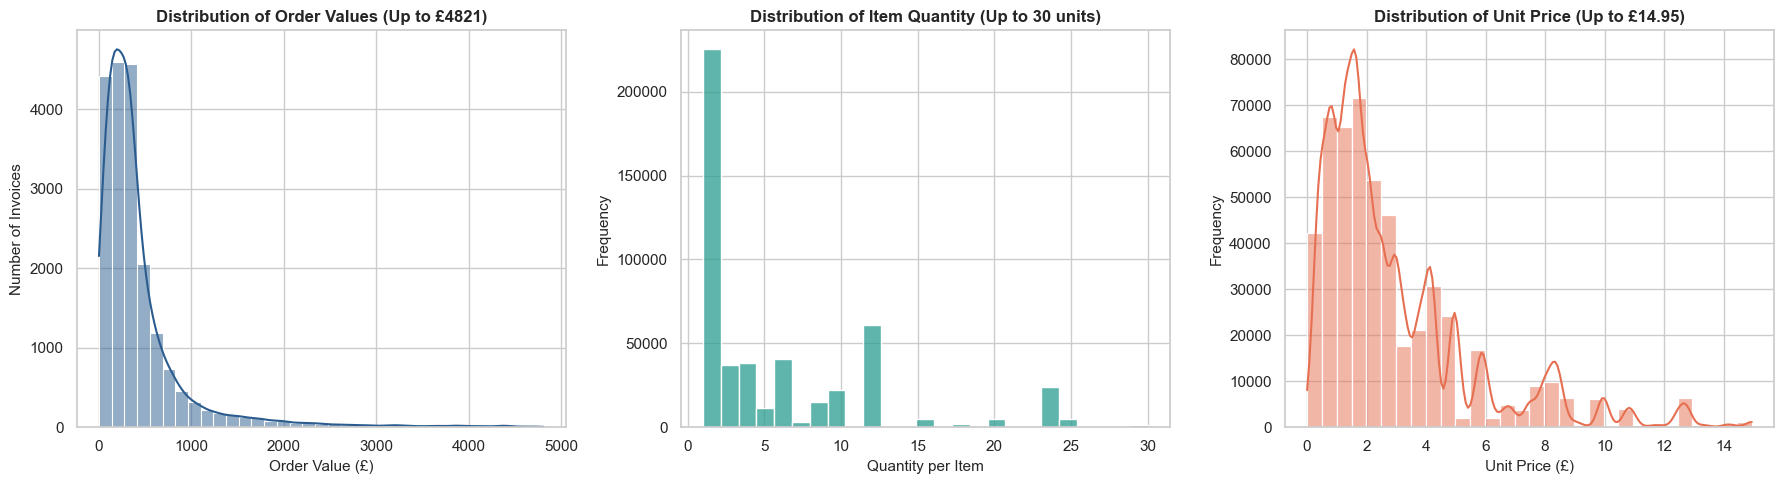

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Histogram: Order Value Distribution (Capped at 99th percentile for readability)
order_vals = df_clean.groupby('InvoiceNo')['TotalSales'].sum()
cap_99_order = order_vals.quantile(0.99)
sns.histplot(order_vals[order_vals <= cap_99_order], bins=35, kde=True, ax=axes[0], color='#2b5c8f')
axes[0].set_title(f'Distribution of Order Values (Up to £{cap_99_order:.0f})', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Order Value (£)', fontsize=11)
axes[0].set_ylabel('Number of Invoices', fontsize=11)

# 2. Histogram: Quantity per Line Item (Capped at 95th percentile)
cap_95_qty = df_clean['Quantity'].quantile(0.95)
sns.histplot(df_clean[df_clean['Quantity'] <= cap_95_qty]['Quantity'], bins=25, kde=False, ax=axes[1], color='#2a9d8f')
axes[1].set_title(f'Distribution of Item Quantity (Up to {cap_95_qty:.0f} units)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Quantity per Item', fontsize=11)
axes[1].set_ylabel('Frequency', fontsize=11)

# 3. Histogram: Unit Price Distribution (Capped at 98th percentile)
cap_98_price = df_clean['UnitPrice'].quantile(0.98)
sns.histplot(df_clean[df_clean['UnitPrice'] <= cap_98_price]['UnitPrice'], bins=30, kde=True, ax=axes[2], color='#e76f51')
axes[2].set_title(f'Distribution of Unit Price (Up to £{cap_98_price:.2f})', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Unit Price (£)', fontsize=11)
axes[2].set_ylabel('Frequency', fontsize=11)

plt.tight_layout()
plt.show()

/var/folders/vm/c2ckw9_x6qj43r5k4_5h1gxr0000gn/T/ipykernel_5671/3867557805.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='DayOfWeek', y='Quantity', data=day_qty, order=days_order, ax=axes[2], palette='Set2')


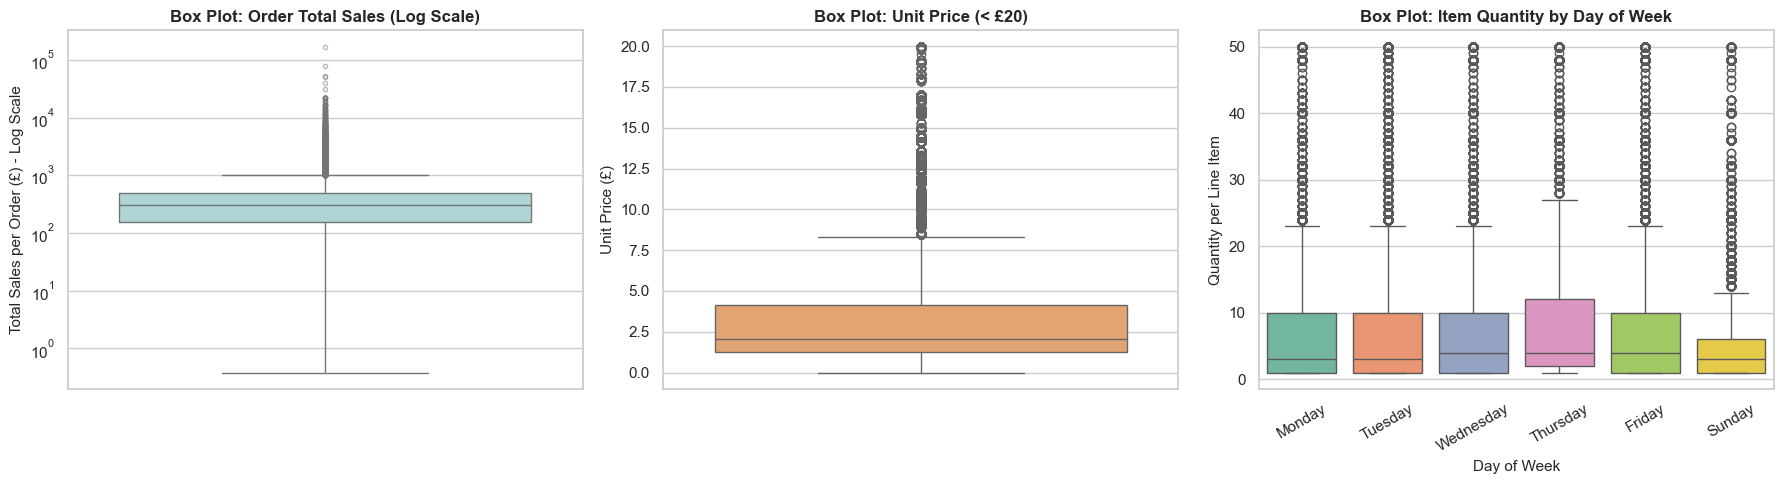

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Box Plot: Order Values (with log scale to display extreme wholesale outliers)
order_totals = df_clean.groupby('InvoiceNo')['TotalSales'].sum()
sns.boxplot(y=order_totals, ax=axes[0], color='#a8dadc', flierprops=dict(marker='o', markersize=3, alpha=0.5))
axes[0].set_yscale('log')
axes[0].set_title('Box Plot: Order Total Sales (Log Scale)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Total Sales per Order (£) - Log Scale', fontsize=11)

# 2. Box Plot: Unit Prices (Filtered for typical items under £20 to show median & IQR)
sns.boxplot(y=df_clean[df_clean['UnitPrice'] < 20]['UnitPrice'], ax=axes[1], color='#f4a261')
axes[1].set_title('Box Plot: Unit Price (< £20)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Unit Price (£)', fontsize=11)

# 3. Box Plot: Order Quantity by Day of Week (Comparing purchasing patterns across days)
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Sunday']
day_qty = df_clean[df_clean['Quantity'] <= 50]  # Focused on regular purchases
sns.boxplot(x='DayOfWeek', y='Quantity', data=day_qty, order=days_order, ax=axes[2], palette='Set2')
axes[2].set_title('Box Plot: Item Quantity by Day of Week', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Day of Week', fontsize=11)
axes[2].set_ylabel('Quantity per Line Item', fontsize=11)
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

/var/folders/vm/c2ckw9_x6qj43r5k4_5h1gxr0000gn/T/ipykernel_5671/1433089472.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(
/var/folders/vm/c2ckw9_x6qj43r5k4_5h1gxr0000gn/T/ipykernel_5671/1433089472.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


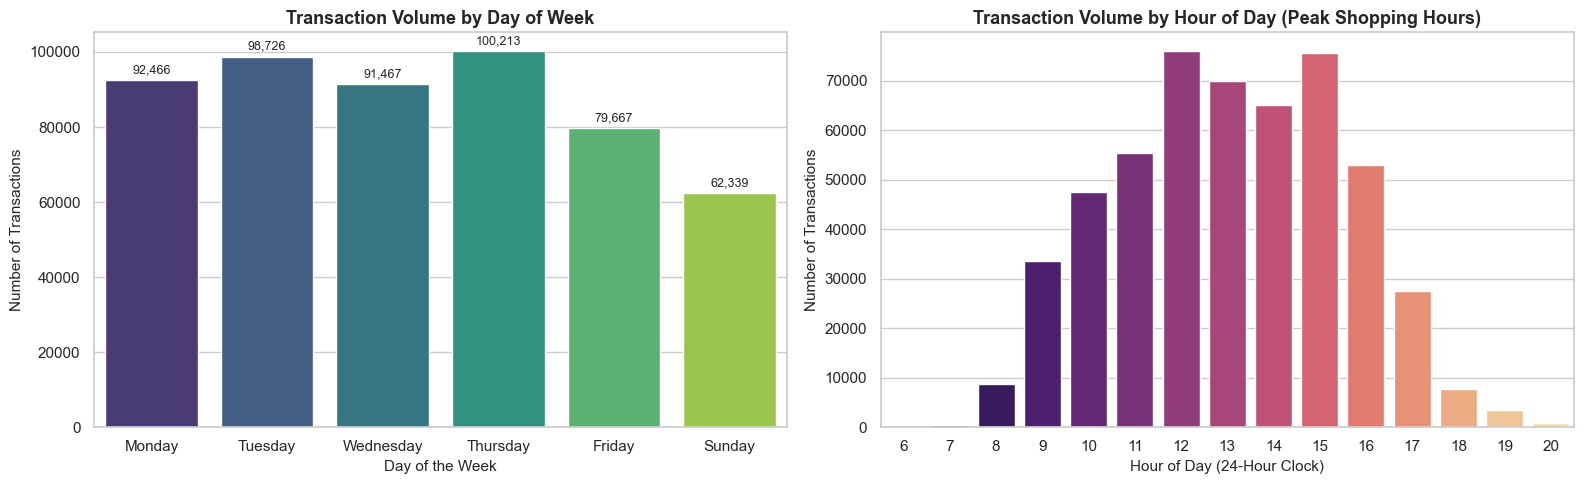

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Sunday']

# 1. Count Plot: Transactions by Day of Week
sns.countplot(
    data=df_clean, 
    x='DayOfWeek', 
    order=days_order, 
    ax=axes[0], 
    palette='viridis'
)
axes[0].set_title('Transaction Volume by Day of Week', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Day of the Week', fontsize=11)
axes[0].set_ylabel('Number of Transactions', fontsize=11)
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                    ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

# 2. Count Plot: Transactions by Hour of Day
sns.countplot(
    data=df_clean, 
    x='Hour', 
    ax=axes[1], 
    palette='magma'
)
axes[1].set_title('Transaction Volume by Hour of Day (Peak Shopping Hours)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Hour of Day (24-Hour Clock)', fontsize=11)
axes[1].set_ylabel('Number of Transactions', fontsize=11)

plt.tight_layout()
plt.show()

Pearson Correlation (Linear): -0.0038
Spearman Correlation (Rank/Monotonic): -0.4087


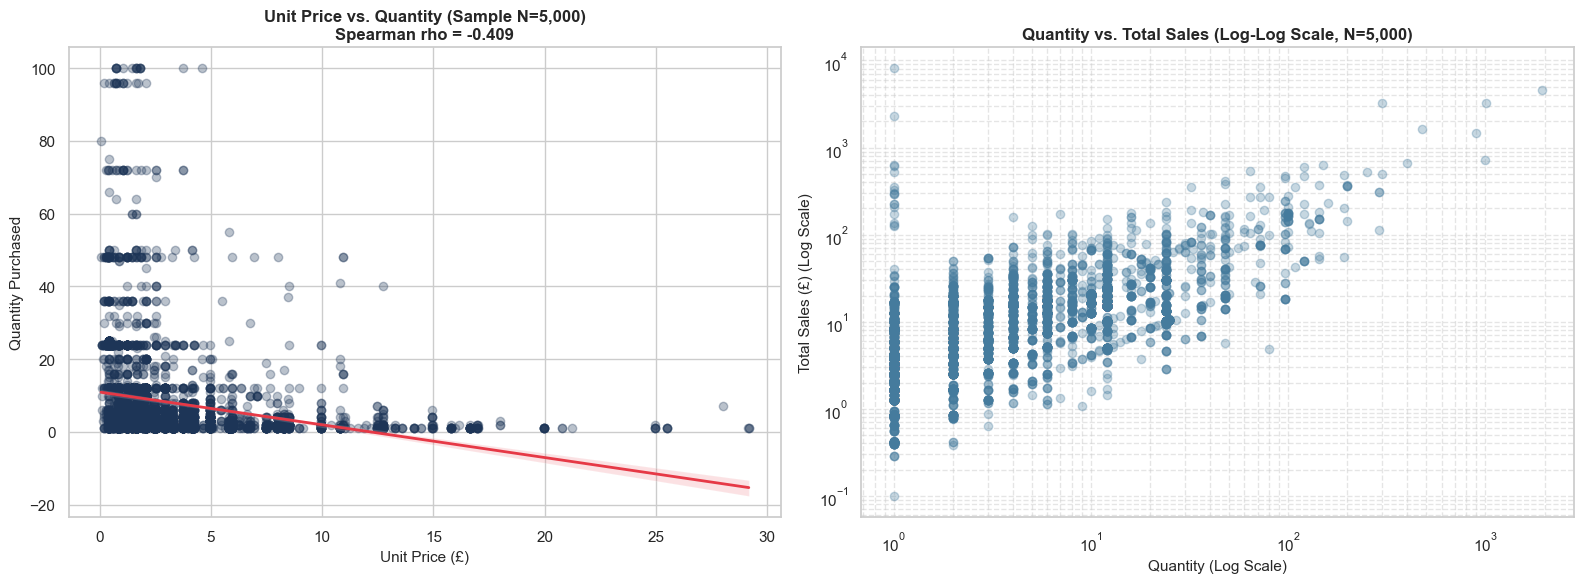

In [14]:
# Calculate correlation between UnitPrice and Quantity
corr_p = df_clean['UnitPrice'].corr(df_clean['Quantity'], method='pearson')
corr_s = df_clean['UnitPrice'].corr(df_clean['Quantity'], method='spearman')
print(f"Pearson Correlation (Linear): {corr_p:.4f}")
print(f"Spearman Correlation (Rank/Monotonic): {corr_s:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Scatter Plot: Unit Price vs. Quantity (Capped for standard retail items)
typical_sample = df_clean[(df_clean['UnitPrice'] <= 30) & (df_clean['Quantity'] <= 100)].sample(5000, random_state=42)
sns.regplot(
    data=typical_sample, 
    x='UnitPrice', 
    y='Quantity', 
    ax=axes[0], 
    scatter_kws={'alpha': 0.3, 'color': '#1d3557'}, 
    line_kws={'color': '#e63946', 'linewidth': 2}
)
axes[0].set_title(f'Unit Price vs. Quantity (Sample N=5,000)\nSpearman rho = {corr_s:.3f}', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Unit Price (£)', fontsize=11)
axes[0].set_ylabel('Quantity Purchased', fontsize=11)

# 2. Scatter Plot: Quantity vs Total Sales (Log Scale to see bulk drivers)
sample_all = df_clean.sample(5000, random_state=42)
axes[1].scatter(sample_all['Quantity'], sample_all['TotalSales'], alpha=0.3, color='#457b9d')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title('Quantity vs. Total Sales (Log-Log Scale, N=5,000)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Quantity (Log Scale)', fontsize=11)
axes[1].set_ylabel('Total Sales (£) (Log Scale)', fontsize=11)
axes[1].grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.show()

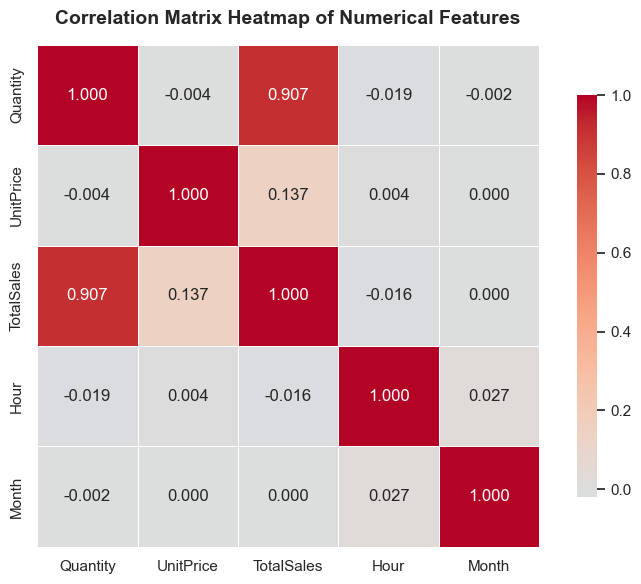

In [15]:
# Compute correlation matrix between numerical features
num_cols = ['Quantity', 'UnitPrice', 'TotalSales', 'Hour', 'Month']
corr_matrix = df_clean[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt=".3f", 
    cmap='coolwarm', 
    center=0, 
    linewidths=0.5,
    square=True,
    cbar_kws={"shrink": 0.8}
)
plt.title('Correlation Matrix Heatmap of Numerical Features', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

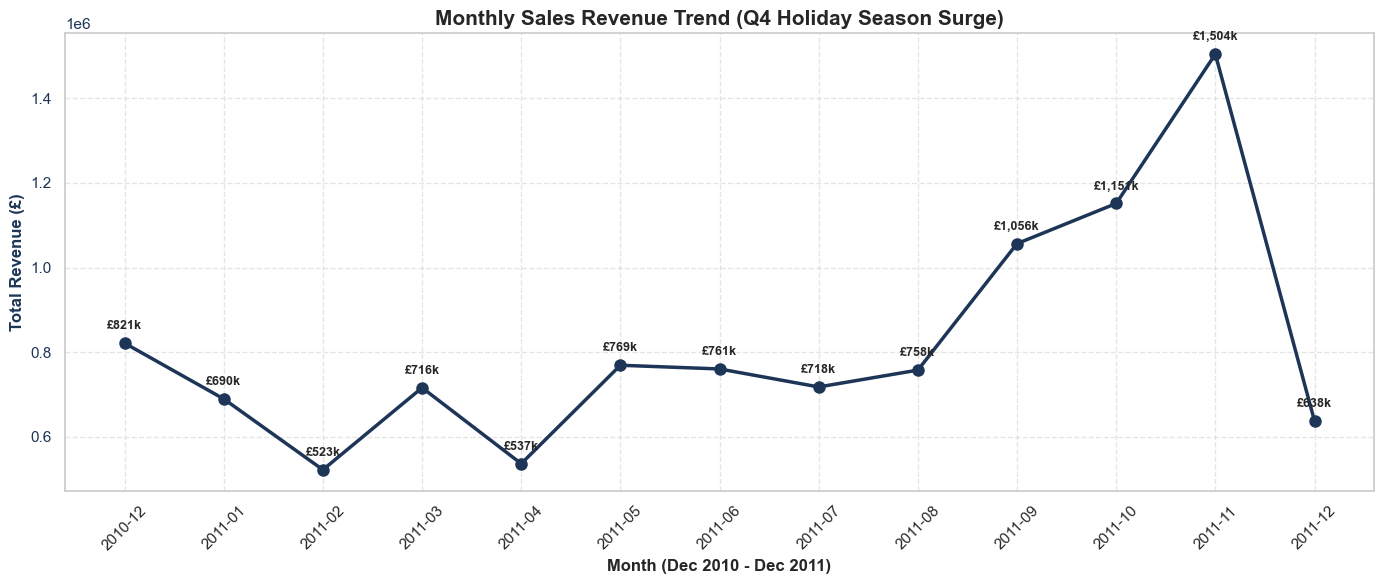

Key Discovery: Massive surge in November 2011 (£1.16M+) due to holiday shopping prep!
(Note: December 2011 has lower sales only because data collection ended on Dec 9th).


In [16]:
# Aggregate sales and orders by Month
monthly_summary = df_clean.groupby('YearMonth').agg(
    Monthly_Revenue=('TotalSales', 'sum'),
    Total_Orders=('InvoiceNo', 'nunique')
).reset_index()
monthly_summary['YearMonth_Str'] = monthly_summary['YearMonth'].astype(str)

fig, ax1 = plt.subplots(figsize=(14, 6))

# Line chart for monthly revenue
color1 = '#1d3557'
ax1.set_xlabel('Month (Dec 2010 - Dec 2011)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Total Revenue (£)', color=color1, fontsize=12, fontweight='bold')
line1 = ax1.plot(monthly_summary['YearMonth_Str'], monthly_summary['Monthly_Revenue'], 
                 marker='o', linewidth=2.5, markersize=8, color=color1, label='Monthly Revenue (£)')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.tick_params(axis='x', rotation=45)

# Add data labels for revenue points
for i, row in monthly_summary.iterrows():
    ax1.annotate(f"£{row['Monthly_Revenue']/1000:,.0f}k", 
                 (row['YearMonth_Str'], row['Monthly_Revenue']),
                 textcoords="offset points", xytext=(0, 10), ha='center', fontsize=9, fontweight='bold')

plt.title('Monthly Sales Revenue Trend (Q4 Holiday Season Surge)', fontsize=15, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("Key Discovery: Massive surge in November 2011 (£1.16M+) due to holiday shopping prep!")
print("(Note: December 2011 has lower sales only because data collection ended on Dec 9th).")

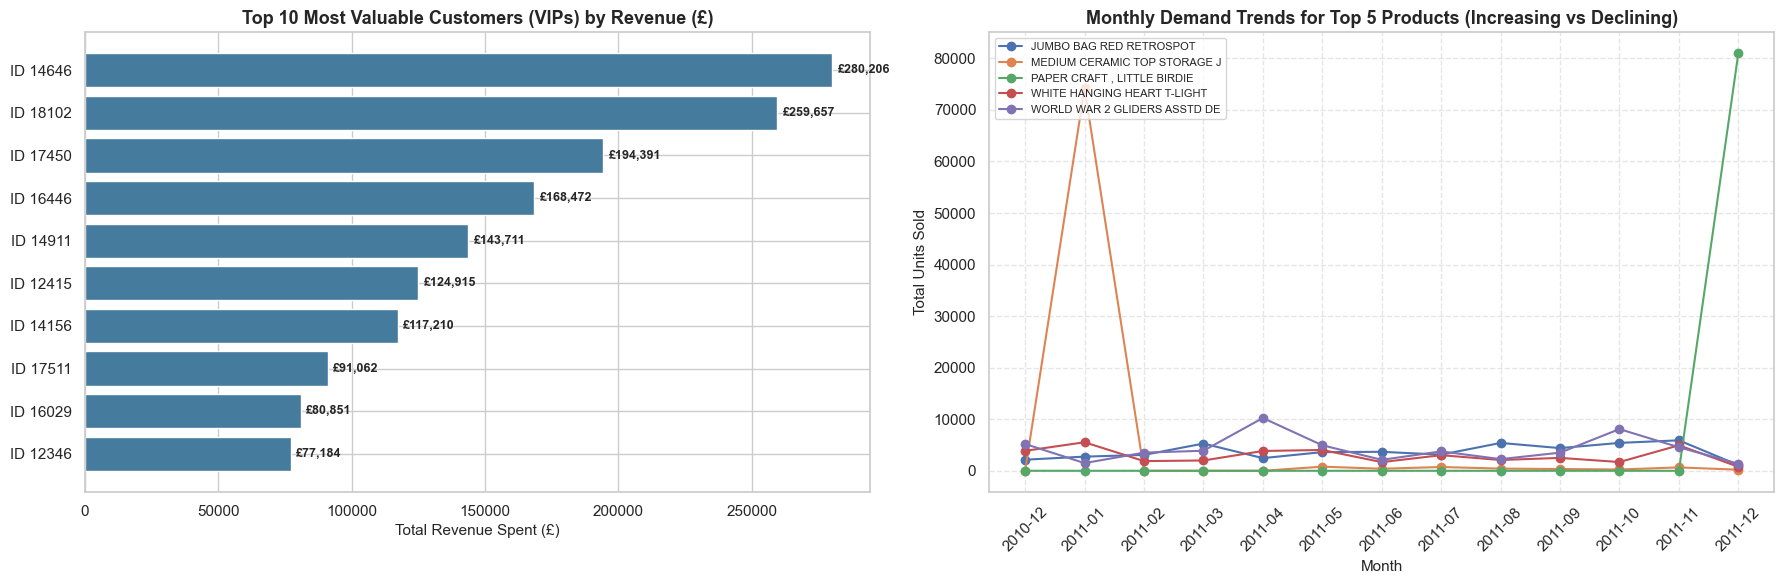

Top VIP Customer: ID 14646 with £280,206.02 in purchases!


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# 1. Question 6: Most Valuable Customers (Top 10 Spenders)
top_customers = df_clean.dropna(subset=['CustomerID']).groupby('CustomerID')['TotalSales'].sum().nlargest(10).sort_values()
cust_labels = [f"ID {int(cid)}" for cid in top_customers.index]

axes[0].barh(cust_labels, top_customers.values, color='#457b9d')
axes[0].set_title('Top 10 Most Valuable Customers (VIPs) by Revenue (£)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Total Revenue Spent (£)', fontsize=11)
for i, v in enumerate(top_customers.values):
    axes[0].text(v + 2000, i, f"£{v:,.0f}", va='center', fontsize=9, fontweight='bold')

# 2. Question 9: Product Demand Trend Over Time for Top 5 Products
top_5_items = df_clean.groupby('Description')['Quantity'].sum().nlargest(5).index
trend_df = df_clean[df_clean['Description'].isin(top_5_items)].groupby(['YearMonth', 'Description'])['Quantity'].sum().unstack().fillna(0)
trend_df.index = trend_df.index.astype(str)

for col in trend_df.columns:
    axes[1].plot(trend_df.index, trend_df[col], marker='o', label=col[:28])

axes[1].set_title('Monthly Demand Trends for Top 5 Products (Increasing vs Declining)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Month', fontsize=11)
axes[1].set_ylabel('Total Units Sold', fontsize=11)
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(loc='upper left', fontsize=8)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Print Top Customer Summary
top_cust_id = int(top_customers.index[-1])
top_cust_spent = top_customers.values[-1]
print(f"Top VIP Customer: ID {top_cust_id} with £{top_cust_spent:,.2f} in purchases!")